In [140]:
# 그래프관련 import 
import matplotlib.pyplot as plt
import matplotlib
matplotlib.rcParams['font.family'] = 'Malgun Gothic'
matplotlib.rcParams['axes.unicode_minus']=False

# 프로그램 
import pandas as pd
import numpy as np
from sklearn import svm,metrics
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import StandardScaler

In [141]:
# 도미 - 35 
bream_length = [25.4, 26.3, 26.5, 29.0, 29.0, 29.7, 29.7, 30.0, 30.0, 30.7, 31.0, 31.0, 31.5, 32.0, 32.0, 32.0, 33.0, 33.0, 33.5, 33.5, 34.0, 34.0, 34.5, 35.0, 35.0, 35.0, 35.0, 36.0, 36.0, 37.0, 38.5, 38.5, 39.5, 41.0, 41.0]
bream_weight = [242.0, 290.0, 340.0, 363.0, 430.0, 450.0, 500.0, 390.0, 450.0, 500.0, 475.0, 500.0, 500.0, 340.0, 600.0, 600.0, 700.0, 700.0, 610.0, 650.0, 575.0, 685.0, 620.0, 680.0, 700.0, 725.0, 720.0, 714.0, 850.0, 1000.0, 920.0, 955.0, 925.0, 975.0, 950.0]

# 빙어 - 14 
smelt_length = [9.8, 10.5, 10.6, 11.0, 11.2, 11.3, 11.8, 11.8, 12.0, 12.2, 12.4, 13.0, 14.3, 15.0]
smelt_weight = [6.7, 7.5, 7.0, 9.7, 9.8, 8.7, 10.0, 9.9, 9.8, 12.2, 13.4, 12.2, 19.7, 19.9]

In [142]:
# 데이터 전처리 
total_length = bream_length + smelt_length
total_weight = bream_weight + smelt_weight  

In [143]:
label = [1]*35 + [0]*14
label = ['도미']*35 + ['빙어']*14

data = np.column_stack((total_length, total_weight))

In [144]:
# data2 = np.array(data)
# data2 = data2 + 2 

# data = [[l,w] for l, w in zip(total_length, total_weigth)] 
# label = [1]*35 + [0]*14

In [ ]:
train_data, test_data, train_label, test_label = \
    train_test_split(data, label)
    
train_data, test_data, train_label, test_label = \
    train_test_split(train_scaled, label)

In [145]:
clf = KNeighborsClassifier()
clf.fit(train_data, train_label)

result = clf.predict(test_data)

score = metrics.accuracy_score(result,test_label)
score = clf.score(test_data,test_label)
print('예측 :', score)



예측 : 1.0


In [146]:
input1 = '25, 120'
input1 = input1.split(',')
input1

input2 = list(map(float,input1))
input2

[25.0, 120.0]

In [147]:
mean = np.mean(data, axis=0)
std = np.std(data, axis=0)

train_scaled = (data-mean)/std
new_data = ([25,120]-mean)/std

In [156]:
from sklearn.preprocessing import StandardScaler
# 정규화 작업 
ss = StandardScaler() # 정규화 선언 

ss.fit(data) 
train_scaled = ss.transform(data)
train_scaled


array([[-0.16326134, -0.62350364],
       [-0.07448421, -0.47571019],
       [-0.05475596, -0.32175867],
       [ 0.19184717, -0.25094097],
       [ 0.19184717, -0.04464594],
       [ 0.26089605,  0.01693467],
       [ 0.26089605,  0.17088618],
       [ 0.29048842, -0.16780715],
       [ 0.29048842,  0.01693467],
       [ 0.3595373 ,  0.17088618],
       [ 0.38912967,  0.09391043],
       [ 0.38912967,  0.17088618],
       [ 0.4384503 ,  0.17088618],
       [ 0.48777093, -0.32175867],
       [ 0.48777093,  0.47878922],
       [ 0.48777093,  0.47878922],
       [ 0.58641218,  0.78669225],
       [ 0.58641218,  0.78669225],
       [ 0.6357328 ,  0.50957952],
       [ 0.6357328 ,  0.63274074],
       [ 0.68505343,  0.40181346],
       [ 0.68505343,  0.7405068 ],
       [ 0.73437406,  0.54036983],
       [ 0.78369468,  0.72511165],
       [ 0.78369468,  0.78669225],
       [ 0.78369468,  0.86366801],
       [ 0.78369468,  0.84827286],
       [ 0.88233593,  0.82979868],
       [ 0.88233593,

In [149]:
# input 받아서 도미인지 빙어인지 확인하시오
# 길이, 무게

input1 = input('생선의 길이와 무게를 입력하시오. (예: 25, 120)')
input1 = input1.split(',')
input1

input2 = list(map(float,input1))
input2
new_input = (input2-mean)/std

# result2 = clf.predict([input2])
result2 = clf.predict([new_input])
print('예측생선 :', result2)

예측생선 : ['도미']


In [ ]:
distances, indexes = clf.kneighbors([new_input]) # 도미로 판단하게 된 데이터가 어떤 데이터인지 알려줌 (판단 근거)
indexes

array([[35, 28, 11, 18, 27]])

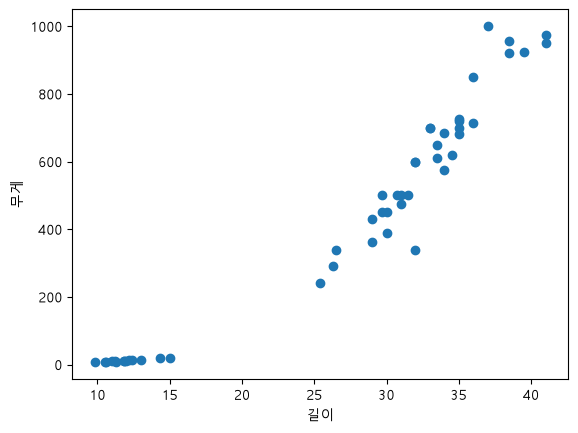

In [ ]:
plt.scatter(data[:,0],data[:,1])
plt.xlabel('길이')
plt.ylabel('무게')
plt.show()

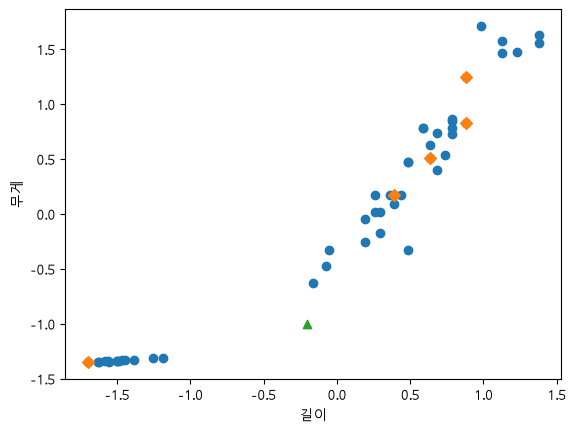

In [153]:
# 그래프 출력
plt.scatter(train_scaled[:,0],train_scaled[:,1])
plt.scatter(train_scaled[indexes,0],train_scaled[indexes,1],marker='D')
plt.scatter(new_input[0],new_input[1],marker='^')
plt.xlabel('길이')
plt.ylabel('무게')
plt.show()